# Instituto Superior de Engenharia do Porto (ISEP)
## Departamento de Engenharia Electrotécnica (DEE)
### Unidade Curricular: Sinais e Sistemas (SINSI)
**Licenciatura em Engenharia Electrotécnica e de Computadores**

---
# Sistemas Lineares e Invariantes no Tempo


### Objetivos:
1. **Compreender o papel central da Resposta ao Impulso**: Compreender que a resposta impulsional $h(t)$ (tempo contínuo) ou $h[n]$ (tempo discreto) contém toda a informação necessária para caraterizar e prever o comportamento de qualquer sistema LIT.
2. **Dominar os Critérios Formais de Classificação a partir de $h$**:
   - **Memória**: Identificar se o sistema é puramente estático ($h(t) = K\delta(t)$ / $h[n] = K\delta[n]$) ou dinâmico com acumulação de energia/atraso temporal.
   - **Causalidade**: Avaliar a condição $h(t) = 0, \forall t < 0$ ou $h[n] = 0, \forall n < 0$ e a sua viabilidade de implementação em tempo real.
   - **Estabilidade BIBO**: Aplicar rigorosamente a condição necessária e suficiente de **integrabilidade absoluta** ($\int_{-\infty}^{+\infty} |h(t)| dt < \infty$) ou **somabilidade absoluta** ($\sum_{n=-\infty}^{+\infty} |h[n]| < \infty$).



## 1. Enquadramento Teórico Formal

### 1.1. O Modelo LIT e o Teorema Fundamental da Convolução
Em Engenharia Electrotécnica, a grande maioria dos circuitos analógicos lineares (redes RLC passivas e ativas com ampop em regime linear), linhas de transmissão e canais de telecomunicações são modelados como **Sistemas Lineares e Invariantes no Tempo (LIT)** (ou *LTI - Linear Time-Invariant*).

Uma propriedade notável dos sistemas LIT é que eles ficam **totalmente caracterizados** pela sua resposta a uma excitação elementar de referência: o **Impulso Unitário** ($\delta(t)$ em tempo contínuo ou $\delta[n]$ em tempo discreto).

$$\text{Tempo Contínuo (TC): } h(t) = \mathcal{T}\{\delta(t)\} \qquad \Big| \qquad \text{Tempo Discreto (TD): } h[n] = \mathcal{T}\{\delta[n]\}$$

```
                            +--------------------------+
       Entrada: x(t) ------>|  Sistema LIT: h(t) / h[n] |------> Saída: y(t) = (x * h)(t)
                            +--------------------------+
```

Pelo princípio da sobreposição (linearidade) e pela invariância no tempo, qualquer sinal arbitrário $x(t)$ (ou $x[n]$) pode ser decomposto numa soma ponderada contínua de impulsos atrasados. Consequentemente, a saída do sistema é calculada através do **Operador Convolução**:

$$\text{Tempo Contínuo: } y(t) = (x * h)(t) = \int_{-\infty}^{+\infty} x(\tau) h(t - \tau) \, d\tau = \int_{-\infty}^{+\infty} h(\tau) x(t - \tau) \, d\tau$$

$$\text{Tempo Discreto: } y[n] = (x * h)[n] = \sum_{k=-\infty}^{+\infty} x[k] h[n - k] = \sum_{k=-\infty}^{+\infty} h[k] x[n - k]$$

---

### 1.2. Critério 1: Memória (Sistemas Estáticos vs. Dinâmicos)
* **Definição Geral**: Um sistema diz-se **sem memória (ou estático)** se o valor da saída no instante presente $t_0$ depender unicamente e em exclusivo do valor da entrada no mesmo instante $t_0$, i.e., $y(t_0) = f(x(t_0))$. Caso dependa de valores da entrada em instantes distintos do presente ($t \neq t_0$), diz-se **com memória (ou dinâmico)**.
* **Condição Necessária e Suficiente para Sistemas LIT**:
  $$y(t) = K \cdot x(t) \iff h(t) = K \, \delta(t), \quad K \in \mathbb{R}$$
  $$y[n] = K \cdot x[n] \iff h[n] = K \, \delta[n], \quad K \in \mathbb{R}$$
* **Demonstração Analítica**:
  Pela integral de convolução:
  $$y(t) = \int_{-\infty}^{+\infty} h(\tau) x(t - \tau) \, d\tau$$
  Para que $y(t)$ dependa unicamente de $x(t)$, o integrando só pode extrair informação de $x(t - \tau)$ quando o desfasamento for nulo ($\tau = 0$). Isso exige que a distribuição $h(\tau)$ seja identicamente nula para todo $\tau \neq 0$. Em tempo contínuo, a única distribuição de suporte pontual $\{0\}$ com integral finita é o impulso de Dirac $\delta(t)$.
* **Regra Prática de Decisão**:
  $$\begin{cases} \mathbf{Sem\ Memória\ (Estático):} & \text{Se } h(t) = K \delta(t) \quad \text{ou} \quad h[n] = K \delta[n] \\ \mathbf{Com\ Memória\ (Dinâmico):} & \text{Se existir qualquer } t \neq 0 \text{ (ou } n \neq 0 \text{) onde } h \neq 0 \end{cases}$$
* *Interpretação Física*: Sistemas estáticos são puramente resistivos ou amplificadores ideais de ganho plano. Sistemas dinâmicos contêm elementos armazenadores de energia (condensadores, bobinas em circuitos analógicos; registadores de deslocamento ou buffers de memória em circuitos digitais).

---

### 1.3. Critério 2: Causalidade (Sistemas Causais vs. Não Causais)
* **Definição Geral**: Um sistema é **causal (não antecipatório)** se a saída no instante presente $t_0$ depender unicamente de valores presentes e passados da entrada ($t \le t_0$ ou $n \le n_0$). Nunca pode depender de valores futuros ($t > t_0$ ou $n > n_0$).
* **Condição Necessária e Suficiente para Sistemas LIT**:
  $$\mathbf{Tempo\ Contínuo:} \quad h(t) = 0, \quad \forall t < 0$$
  $$\mathbf{Tempo\ Discreto:} \quad h[n] = 0, \quad \forall n < 0$$
* **Demonstração Analítica**:
  Escrevamos a convolução decompondo o intervalo de integração em valores passados/presentes e valores futuros da entrada:
  $$y(t) = \int_{-\infty}^{+\infty} h(\tau) x(t - \tau) \, d\tau = \underbrace{\int_{-\infty}^{0^-} h(\tau) x(t - \tau) \, d\tau}_{\text{Para } \tau < 0 \implies t - \tau > t \text{ (Futuro)}} + \underbrace{\int_{0}^{+\infty} h(\tau) x(t - \tau) \, d\tau}_{\text{Para } \tau \ge 0 \implies t - \tau \le t \text{ (Passado/Presente)}}$$
  Para que a saída $y(t)$ seja completamente independente do futuro da entrada ($x(t - \tau)$ com $\tau < 0$) para qualquer sinal $x(t)$, a única solução matemática universal é que $h(\tau) \equiv 0$ para todo $\tau < 0$.
* *Interpretação Física*: Na natureza e em sistemas a operar em tempo real, o futuro é inacessível; um sistema físico excitado em $t=0$ não pode produzir qualquer resposta antes do próprio estímulo acontecer ($t < 0$). Sistemas não causais só existem em pós-processamento de sinais já previamente gravados (e.g., filtragem de ficheiros áudio, processamento de imagem médica bidimensional).

---

### 1.4. Critério 3: Estabilidade BIBO (*Bounded-Input, Bounded-Output*)
* **Definição Geral**: Um sistema é estável no sentido BIBO se e só se **toda e qualquer** entrada limitada em amplitude produzir uma saída garantidamente limitada em amplitude:
  $$\text{Se } |x(t)| \le M_x < \infty, \; \forall t \implies |y(t)| \le M_y < \infty, \; \forall t$$
* **Condição Necessária e Suficiente para Sistemas LIT**:
  $$\mathbf{Tempo\ Contínuo:} \quad I = \int_{-\infty}^{+\infty} |h(t)| \, dt < \infty \quad \text{(Resposta Impulsional Absolutamente Integrável)}$$
  $$\mathbf{Tempo\ Discreto:} \quad S = \sum_{n=-\infty}^{+\infty} |h[n]| < \infty \quad \text{(Resposta Impulsional Absolutamente Somável)}$$
* **Demonstração Analítica Formal**:
  1. **Suficiência (Provar que $I < \infty \implies$ BIBO Estável)**:
     Seja uma entrada limitada qualquer $|x(t)| \le M_x < \infty$. Aplicando a desigualdade triangular às integrais:
     $$|y(t)| = \left| \int_{-\infty}^{+\infty} h(\tau) x(t - \tau) \, d\tau \right| \le \int_{-\infty}^{+\infty} |h(\tau) x(t - \tau)| \, d\tau = \int_{-\infty}^{+\infty} |h(\tau)| \cdot |x(t - \tau)| \, d\tau$$
     Como $|x(t - \tau)| \le M_x$ para todo $\tau$:
     $$|y(t)| \le M_x \int_{-\infty}^{+\infty} |h(\tau)| \, d\tau = M_x \cdot I$$
     Se $I < \infty$, então a amplitude da saída é estritamente majorada por $M_y = M_x \cdot I < \infty$ em qualquer instante $t$. Logo, o sistema é estável.
  2. **Necessidade (Provar que se $I = \infty$, o sistema é Instável)**:
     Basta encontrar um contra-exemplo: uma entrada limitada que faça a saída divergir. Suponhamos $I = \infty$ e consideremos a entrada limitada com $|x(t)| = 1 \le 1$:
     $$x(t) = \operatorname{sgn}(h(-t))$$
     Avaliando a saída no instante $t = 0$:
     $$y(0) = \int_{-\infty}^{+\infty} h(\tau) x(-\tau) \, d\tau = \int_{-\infty}^{+\infty} h(\tau) \operatorname{sgn}(h(\tau)) \, d\tau = \int_{-\infty}^{+\infty} |h(\tau)| \, d\tau = I = \infty$$
     A saída em $t=0$ diverge para $+\infty$, comprovando que $I < \infty$ é uma condição estritamente necessária.

---

### 1.5. Propriedades do Impulso de Dirac $\delta(t)$
O impulso de Dirac $\delta(t)$ não é uma função clássica ordinária, mas sim uma distribuição definida pela sua ação sob integração:
1. **Propriedade da Amostragem (ou Peneiramento)**: Se $g(t)$ for contínua no ponto $t = t_0$:
   $$g(t) \, \delta(t - t_0) = g(t_0) \, \delta(t - t_0)$$
2. **Propriedade da Integração Total**:
   $$\int_{-\infty}^{+\infty} g(t) \, \delta(t - t_0) \, dt = g(t_0)$$


In [1]:
# ====================================================================
# CONFIGURAÇÃO DO AMBIENTE COMPUTACIONAL & VISUALIZAÇÃO GRÁFICA
# ====================================================================
import numpy as np
import matplotlib.pyplot as plt
import scipy.integrate as integrate
import pandas as pd

# Configuração estética profissional para Engenharia Electrotécnica
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 11
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.5
plt.rcParams['grid.linestyle'] = '--'
plt.rcParams['lines.linewidth'] = 2.0

print("Ambiente Python configurado com sucesso!")
print("Bibliotecas carregadas: NumPy, SciPy, Matplotlib e Pandas.")


Ambiente Python configurado com sucesso!
Bibliotecas carregadas: NumPy, SciPy, Matplotlib e Pandas.


---
## Exercício 2 a)
### Resposta Impulsional: $$h(t) = e^{-2t} \, u(t - 2)$$
*(Decaimento exponencial causal contínuo com atraso puro de transporte de $2\text{ s}$)*

---

### Resolução Analítica Passo a Passo

#### 1. Memória (Estático vs. Dinâmico)
* **Condição Teórica**: Um sistema LIT em tempo contínuo é estático (sem memória) se e só se $h(t) = K \delta(t)$.
* **Análise de $h(t)$**:
  $$h(t) = \begin{cases} e^{-2t}, & t \ge 2 \\ 0, & t < 2 \end{cases}$$
  A resposta ao impulso não está concentrada exclusivamente no instante $t = 0$; pelo contrário, estende-se ao longo do intervalo de tempo contínuo $[2, +\infty[$.
* **Conclusão**: O sistema **TEM MEMÓRIA (Dinâmico)**.
  *(A saída no instante $t$ é uma média ponderada das entradas passadas $x(t-\tau)$ para $\tau \ge 2$).*

---

#### 2. Causalidade
* **Condição Teórica**: O sistema é causal se e só se $h(t) = 0$ para todo $t < 0$.
* **Análise de $h(t)$**:
  O fator degrau unitário deslocado é definido por $u(t - 2) = 1$ para $t \ge 2$ e $u(t - 2) = 0$ para $t < 2$.
  Para todo o semi-eixo negativo $t < 0$, temos garantidamente $t < 2$, pelo que:
  $$h(t) = 0, \quad \forall t < 0$$
  De facto, a resposta do sistema permanece identicamente nula em todo o intervalo $]-\infty, 2[$, apresentando um atraso puro de tempo morto (*dead time*) de $2\text{ s}$.
* **Conclusão**: O sistema é **CAUSAL**.

---

#### 3. Estabilidade BIBO
* **Condição Teórica**: O sistema é BIBO estável se e só se $h(t)$ for absolutamente integrável:
  $$I = \int_{-\infty}^{+\infty} |h(t)| \, dt < \infty$$
* **Cálculo da Integral**:
  Como $h(t) \ge 0$ para todo $t$:
  $$I = \int_{-\infty}^{+\infty} |e^{-2t} u(t - 2)| \, dt = \int_{2}^{+\infty} e^{-2t} \, dt$$
  Calculando a primitiva:
  $$I = \lim_{T \to +\infty} \left[ -\frac{1}{2} e^{-2t} \right]_{2}^{T} = \lim_{T \to +\infty} \left( -\frac{1}{2} e^{-2T} \right) - \left( -\frac{1}{2} e^{-2(2)} \right)$$
  Como $\lim_{T \to +\infty} e^{-2T} = 0$:
  $$I = 0 + \frac{1}{2} e^{-4} = \frac{e^{-4}}{2} \approx 0.0091578 < \infty$$
* **Conclusão**: Como $I$ é finito ($I \approx 9.16 \times 10^{-3} < \infty$), o sistema é **ESTÁVEL (BIBO)**.
  *(Qualquer entrada limitada em amplitude $|x(t)| \le M_x$ garante uma saída limitada por $|y(t)| \le M_x \cdot \frac{e^{-4}}{2}$).*


--- Exercício 2 a) ---
Valor analítico da integral absoluta:  I = exp(-4)/2 = 0.00915782
Valor numérico obtido (scipy.quad):    I = 0.00915782 (Erro est.: 4.59e-09)
Critério BIBO: I < inf -> SISTEMA ESTÁVEL (BIBO)


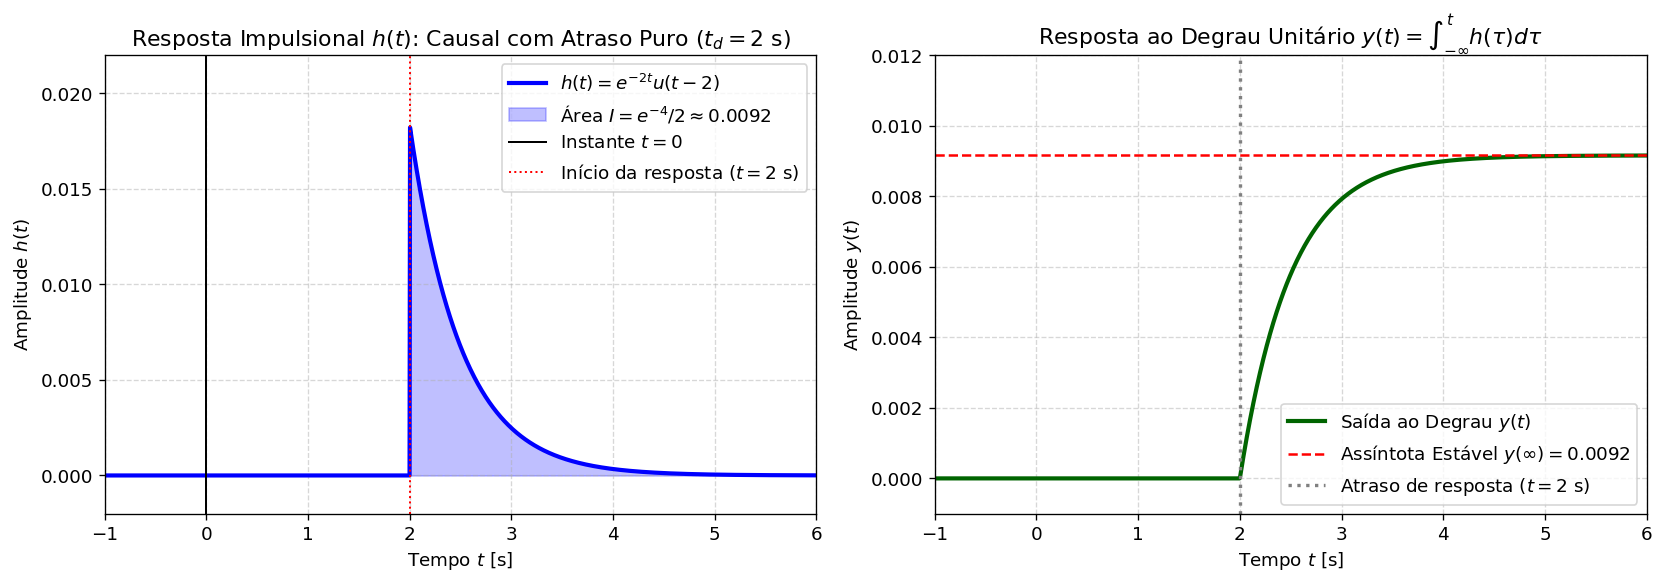

In [2]:
# ====================================================================
# SIMULAÇÃO COMPUTACIONAL — Exercício 2 a): h(t) = exp(-2t) u(t - 2)
# ====================================================================

# 1. Definição do vetor temporal e da resposta impulsional h(t)
t = np.linspace(-1, 6, 1500)
h_2a = np.where(t >= 2.0, np.exp(-2.0 * t), 0.0)

# 2. Integração numérica com SciPy quad e comparação analítica
I_analitico = 0.5 * np.exp(-4.0)
I_numerico, err = integrate.quad(lambda tau: np.exp(-2.0 * tau), 2.0, np.inf)

print(f"--- Exercício 2 a) ---")
print(f"Valor analítico da integral absoluta:  I = exp(-4)/2 = {I_analitico:.8f}")
print(f"Valor numérico obtido (scipy.quad):    I = {I_numerico:.8f} (Erro est.: {err:.2e})")
print(f"Critério BIBO: I < inf -> SISTEMA ESTÁVEL (BIBO)")

# 3. Simulação da Resposta ao Degrau Unitário x(t) = u(t)
# Resposta analítica: y(t) = int_{2}^t exp(-2 tau) d tau = (exp(-4) - exp(-2t))/2 para t >= 2
y_degrau_analitico = np.where(t >= 2.0, (np.exp(-4.0) - np.exp(-2.0 * t)) / 2.0, 0.0)

# Visualização gráfica
fig, axs = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Resposta ao Impulso h(t)
axs[0].plot(t, h_2a, 'b-', lw=2.5, label=r'$h(t) = e^{-2t}u(t-2)$')
axs[0].fill_between(t, h_2a, where=(t >= 2.0), color='blue', alpha=0.25,
                    label=f'Área $I = e^{{-4}}/2 \\approx {I_analitico:.4f}$')
axs[0].axvline(0, color='black', lw=1.2, linestyle='-', label='Instante $t=0$')
axs[0].axvline(2, color='red', lw=1.2, linestyle=':', label='Início da resposta ($t=2$ s)')
axs[0].set_title(r'Resposta Impulsional $h(t)$: Causal com Atraso Puro ($t_d = 2$ s)')
axs[0].set_xlabel(r'Tempo $t$ [s]')
axs[0].set_ylabel(r'Amplitude $h(t)$')
axs[0].legend(loc='upper right')
axs[0].set_xlim([-1, 6])
axs[0].set_ylim([-0.002, 0.022])

# Subplot 2: Resposta ao Degrau x(t) = u(t) comprovando estabilidade BIBO
axs[1].plot(t, y_degrau_analitico, 'darkgreen', lw=2.5, label=r'Saída ao Degrau $y(t)$')
axs[1].axhline(I_analitico, color='red', linestyle='--', lw=1.5,
               label=rf'Assíntota Estável $y(\infty) = {I_analitico:.4f}$')
axs[1].axvline(2, color='gray', linestyle=':', label='Atraso de resposta ($t=2$ s)')
axs[1].set_title(r'Resposta ao Degrau Unitário $y(t) = \int_{-\infty}^t h(\tau)d\tau$')
axs[1].set_xlabel(r'Tempo $t$ [s]')
axs[1].set_ylabel(r'Amplitude $y(t)$')
axs[1].legend(loc='lower right')
axs[1].set_xlim([-1, 6])
axs[1].set_ylim([-0.001, 0.012])

plt.tight_layout()
plt.show()


---
## Exercício 2 b)
### Resposta Impulsional: $$h(t) = e^{-4t} \, u(3 - t)$$
*(Exponencial com inversão temporal e corte superior em $t = 3\text{ s}$)*

---

### Resolução Analítica Passo a Passo

#### 1. Memória (Estático vs. Dinâmico)
* **Condição Teórica**: Um sistema LIT contínuo é estático se e só se $h(t) = K \delta(t)$.
* **Análise de $h(t)$**:
  O degrau invertido $u(3 - t)$ vale $1$ para $3 - t \ge 0 \iff t \le 3$, e $0$ para $t > 3$:
  $$h(t) = \begin{cases} e^{-4t}, & t \le 3 \\ 0, & t > 3 \end{cases}$$
  A resposta ao impulso distribui-se de forma contínua em todo o intervalo $]-\infty, 3]$, não sendo proporcional ao impulso de Dirac $\delta(t)$.
* **Conclusão**: O sistema **TEM MEMÓRIA (Dinâmico)**.

---

#### 2. Causalidade
* **Condição Teórica**: O sistema é causal se e só se $h(t) = 0$ para todo $t < 0$.
* **Análise de $h(t)$**:
  Avaliando para qualquer instante temporal negativo $t < 0$:
  $$t < 0 \implies 3 - t > 3 > 0 \implies u(3 - t) = 1 \implies h(t) = e^{-4t} \neq 0$$
  Por exemplo, para $t = -1\text{ s}$ e $t = -2\text{ s}$:
  $$h(-1) = e^{-4(-1)} = e^4 \approx 54.598 \neq 0$$
  $$h(-2) = e^{-4(-2)} = e^8 \approx 2980.96 \neq 0$$
  Como a resposta ao impulso é não nula muito antes do instante de excitação $t = 0$, a saída no presente $y(t_0)$ depende de valores estritamente futuros da entrada ($x(t)$ com $t > t_0$).
* **Conclusão**: O sistema é **NÃO CAUSAL (Antecipatório)**.

---

#### 3. Estabilidade BIBO
* **Condição Teórica**: O sistema é BIBO estável se e só se $h(t)$ for absolutamente integrável:
  $$I = \int_{-\infty}^{+\infty} |h(t)| \, dt < \infty$$
* **Cálculo da Integral**:
  Como $e^{-4t} > 0$:
  $$I = \int_{-\infty}^{3} e^{-4t} \, dt = \lim_{T \to -\infty} \int_{T}^{3} e^{-4t} \, dt$$
  Calculando a primitiva:
  $$I = \lim_{T \to -\infty} \left[ -\frac{1}{4} e^{-4t} \right]_{T}^{3} = \lim_{T \to -\infty} \left( -\frac{1}{4} e^{-12} - \left( -\frac{1}{4} e^{-4T} \right) \right) = -\frac{1}{4} e^{-12} + \frac{1}{4} \lim_{T \to -\infty} e^{-4T}$$
  Fazendo a substituição de variável $T = -\tau$ com $\tau \to +\infty$:
  $$\lim_{T \to -\infty} e^{-4T} = \lim_{\tau \to +\infty} e^{4\tau} = +\infty$$
  Logo:
  $$I = -\frac{1}{4}e^{-12} + \infty = +\infty$$
* **Conclusão**: A integral diverge ($I = \infty$). O sistema é **INSTÁVEL (BIBO)**.
  *(Uma entrada perfeitamente limitada como $x(t) = 1, \forall t$ excita a cauda exponencial infinita, fazendo a saída explodir para o infinito).*


--- Exercício 2 b) ---
Valor de h(t) em t = -0.5 s: 7.39
Valor de h(t) em t = -1.0 s: 54.60
Valor de h(t) em t = -2.0 s: 2980.96
Integral parcial de -1 até 3: 12.58
Integral parcial de -3 até 3: 4.07e+04
Conclusão: Integral diverge exponencialmente para inf quando T -> -inf -> INSTÁVEL


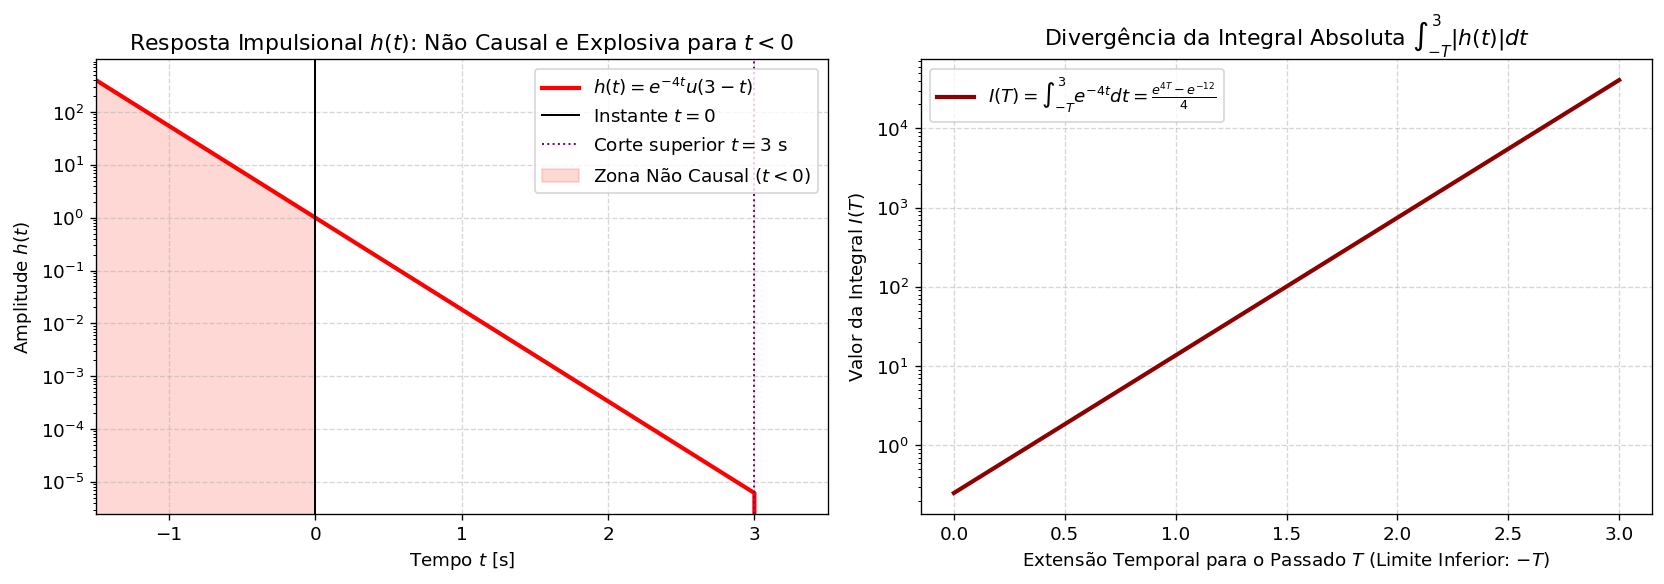

In [3]:
# ====================================================================
# SIMULAÇÃO COMPUTACIONAL — Exercício 2 b): h(t) = exp(-4t) u(3 - t)
# ====================================================================

# 1. Definição do vetor de tempo para visualização de h(t)
t_b = np.linspace(-1.5, 3.5, 1000)
h_2b = np.where(t_b <= 3.0, np.exp(-4.0 * t_b), 0.0)

# 2. Análise da divergência da integral com limite inferior T decrescente
T_vals = np.linspace(0, 3.0, 50)  # T de 0 a 3 (ou seja, integrar de -T até 3)
integrals = []
for T in T_vals:
    # int_{-T}^3 exp(-4t) dt = (exp(4T) - exp(-12)) / 4
    val = (np.exp(4.0 * T) - np.exp(-12.0)) / 4.0
    integrals.append(val)

print(f"--- Exercício 2 b) ---")
print(f"Valor de h(t) em t = -0.5 s: {np.exp(-4*(-0.5)):.2f}")
print(f"Valor de h(t) em t = -1.0 s: {np.exp(-4*(-1.0)):.2f}")
print(f"Valor de h(t) em t = -2.0 s: {np.exp(-4*(-2.0)):.2f}")
print(f"Integral parcial de -1 até 3: {integrals[int(len(integrals)*1/3)]:.2f}")
print(f"Integral parcial de -3 até 3: {integrals[-1]:.2e}")
print("Conclusão: Integral diverge exponencialmente para inf quando T -> -inf -> INSTÁVEL")

# Visualização gráfica
fig, axs = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Resposta ao Impulso com explosão em tempos negativos
axs[0].plot(t_b, h_2b, 'r-', lw=2.5, label=r'$h(t) = e^{-4t}u(3-t)$')
axs[0].axvline(0, color='black', lw=1.2, linestyle='-', label='Instante $t=0$')
axs[0].axvline(3, color='purple', lw=1.2, linestyle=':', label='Corte superior $t=3$ s')
axs[0].fill_between(t_b, h_2b, where=(t_b < 0), color='salmon', alpha=0.3,
                    label='Zona Não Causal ($t < 0$)')
axs[0].set_title(r'Resposta Impulsional $h(t)$: Não Causal e Explosiva para $t < 0$')
axs[0].set_xlabel(r'Tempo $t$ [s]')
axs[0].set_ylabel(r'Amplitude $h(t)$')
axs[0].set_yscale('log')
axs[0].legend(loc='upper right')
axs[0].set_xlim([-1.5, 3.5])

# Subplot 2: Divergência da Integral Absoluta
axs[1].plot(T_vals, integrals, 'darkred', lw=2.5,
            label=r'$I(T) = \int_{-T}^{3} e^{-4t}dt = \frac{e^{4T} - e^{-12}}{4}$')
axs[1].set_title(r'Divergência da Integral Absoluta $\int_{-T}^{3} |h(t)|dt$')
axs[1].set_xlabel(r'Extensão Temporal para o Passado $T$ (Limite Inferior: $-T$)')
axs[1].set_ylabel(r'Valor da Integral $I(T)$')
axs[1].set_yscale('log')
axs[1].legend(loc='upper left')

plt.tight_layout()
plt.show()


---
## Exercício 2 f)
### Resposta Impulsional: $$h(t) = 6e^{-t} \cos(2t) \, \delta(t)$$
*(Modulação de Dirac com termo exponencial amortecido e oscilatório)*

---

### Resolução Analítica Passo a Passo

#### 1. Simplificação Algébrica Fundamental (Propriedade da Amostragem)
* **Teorema do Peneiramento/Amostragem de Dirac**:
  Seja $g(t)$ uma função contínua em $t = 0$. A multiplicação da função pelo impulso de Dirac $\delta(t)$ retém unicamente o valor da função no ponto singular $t = 0$:
  $$g(t) \, \delta(t) = g(0) \, \delta(t)$$
* **Aplicação ao Sistema**:
  Identificando a função multiplicadora:
  $$g(t) = 6e^{-t} \cos(2t)$$
  Como $g(t)$ é de classe $C^\infty$ e, portanto, perfeitamente contínua em $t = 0$:
  $$g(0) = 6 e^{-0} \cos(2 \cdot 0) = 6 \cdot 1 \cdot \cos(0) = 6 \cdot 1 \cdot 1 = 6$$
  Substituindo diretamente na expressão da resposta ao impulso:
  $$h(t) = g(0) \, \delta(t) = 6 \, \delta(t)$$

---

#### 2. Memória (Estático vs. Dinâmico)
* **Condição Teórica**: Um sistema LIT contínuo é estático (sem memória) se e só se $h(t) = K \delta(t)$, com $K \in \mathbb{R}$.
* **Análise da Relação Entrada-Saída**:
  $$y(t) = x(t) * h(t) = x(t) * [6 \delta(t)] = 6 [x(t) * \delta(t)] = 6 \, x(t)$$
  A saída em qualquer instante $t$ depende **exclusivamente e instantaneamente** do valor da entrada no mesmo instante $t$, escalado por um fator de ganho puro $K = 6$.
  Não depende de valores passados nem futuros da entrada.
* **Conclusão**: O sistema é **SEM MEMÓRIA (Estático)**.
  *(Comportamento equivalente a um amplificador puramente resistivo ideal com ganho de tensão $A_v = 6$).*

---

#### 3. Causalidade
* **Condição Teórica**: Um sistema LIT contínuo é causal se e só se $h(t) = 0$ para todo $t < 0$.
* **Análise de $h(t)$**:
  Como $h(t) = 6 \delta(t)$, o seu suporte concentra-se unicamente em $t = 0$. Para todo $t < 0$:
  $$h(t) = 0, \quad \forall t < 0$$
* **Conclusão**: O sistema é **CAUSAL**.
  *(Nota Pedagógica: Todo e qualquer sistema sem memória é obrigatoriamente causal, uma vez que nunca consulta instantes fora do presente).*

---

#### 4. Estabilidade BIBO
* **Condição Teórica**: Integrabilidade absoluta da resposta ao impulso:
  $$I = \int_{-\infty}^{+\infty} |h(t)| \, dt < \infty$$
* **Cálculo da Integral**:
  $$I = \int_{-\infty}^{+\infty} |6 \delta(t)| \, dt = 6 \int_{-\infty}^{+\infty} \delta(t) \, dt = 6 \cdot 1 = 6 < \infty$$
  Em termos da definição direta BIBO: se a entrada for limitada por $|x(t)| \le M_x < \infty, \forall t$:
  $$|y(t)| = |6 x(t)| = 6 |x(t)| \le 6 M_x < \infty$$
* **Conclusão**: Como $I = 6 < \infty$ e a saída é limitada por $M_y = 6M_x$, o sistema é **ESTÁVEL (BIBO)**.


--- Exercício 2 f) ---
Função g(t) = 6*exp(-t)*cos(2t) em t = 0: g(0) = 6.0000
Resposta simplificada: h(t) = 6 * delta(t)
Integral absoluta: I = int |6 delta(t)| dt = 6.0 < inf -> BIBO ESTÁVEL
Relação entrada-saída: y(t) = 6 * x(t) -> SEM MEMÓRIA e CAUSAL


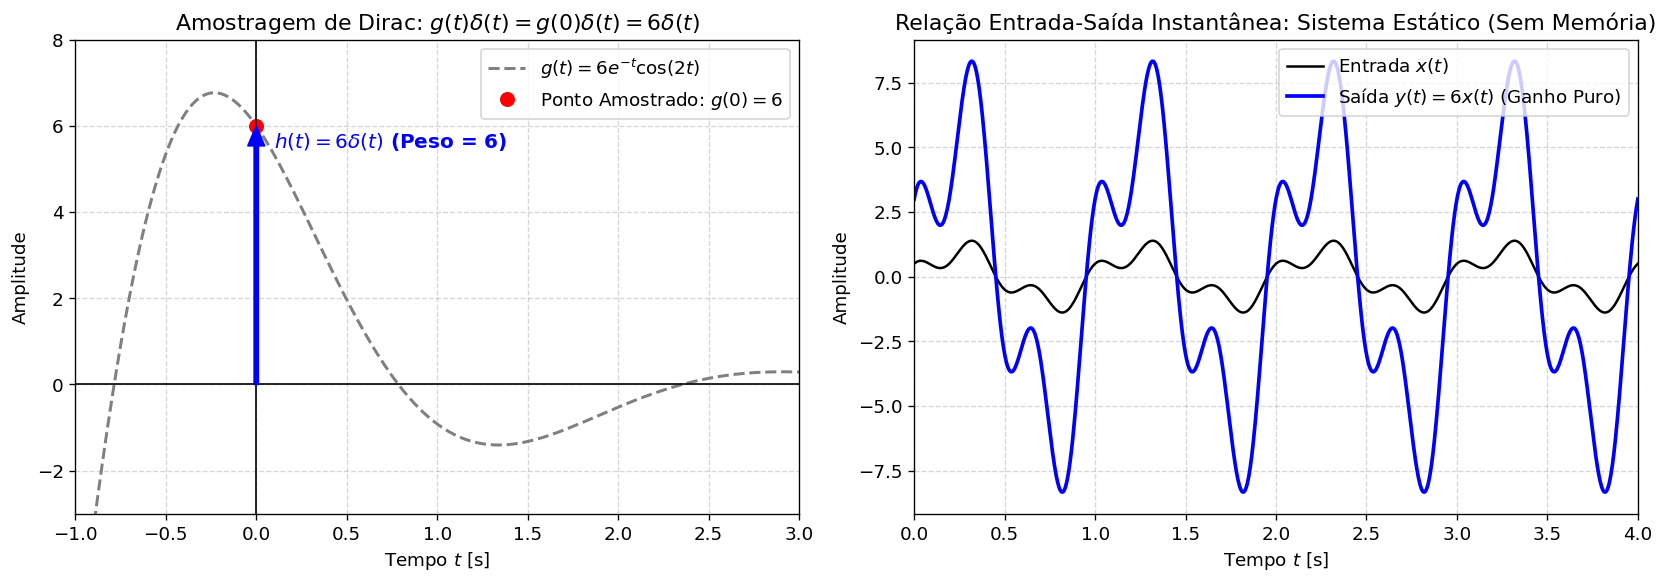

In [4]:
# ====================================================================
# SIMULAÇÃO COMPUTACIONAL — Exercício 2 f): h(t) = 6 exp(-t) cos(2t) delta(t)
# ====================================================================

# 1. Sinal contínuo de amostragem g(t) = 6 exp(-t) cos(2t)
t_f = np.linspace(-1, 3, 1000)
g_t = 6.0 * np.exp(-t_f) * np.cos(2.0 * t_f)
g_0 = 6.0 * np.exp(0.0) * np.cos(0.0)

print(f"--- Exercício 2 f) ---")
print(f"Função g(t) = 6*exp(-t)*cos(2t) em t = 0: g(0) = {g_0:.4f}")
print(f"Resposta simplificada: h(t) = 6 * delta(t)")
print(f"Integral absoluta: I = int |6 delta(t)| dt = 6.0 < inf -> BIBO ESTÁVEL")
print(f"Relação entrada-saída: y(t) = 6 * x(t) -> SEM MEMÓRIA e CAUSAL")

# 2. Simulação de um sinal de teste contínuo arbitrário x(t)
t_sig = np.linspace(0, 4, 1000)
x_sig = np.sin(2.0 * np.pi * 1.0 * t_sig) + 0.5 * np.cos(2.0 * np.pi * 3.0 * t_sig)
y_sig = 6.0 * x_sig  # Resposta instantânea do sistema

# Visualização gráfica
fig, axs = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Visualização da Propriedade de Amostragem do Impulso
axs[0].plot(t_f, g_t, 'gray', lw=1.8, linestyle='--', label=r'$g(t) = 6e^{-t}\cos(2t)$')
axs[0].plot(0, g_0, 'ro', markersize=8, label=r'Ponto Amostrado: $g(0) = 6$')
# Representação padrão de Dirac por seta vertical de altura proporcional à área (peso = 6)
axs[0].annotate('', xy=(0, 6.0), xytext=(0, 0),
                arrowprops=dict(facecolor='blue', edgecolor='blue', width=2.5, headwidth=10))
axs[0].text(0.1, 5.5, r'$h(t) = 6\delta(t)$ (Peso = 6)', color='blue', fontsize=12, fontweight='bold')
axs[0].axvline(0, color='black', lw=1.0)
axs[0].axhline(0, color='black', lw=1.0)
axs[0].set_title(r'Amostragem de Dirac: $g(t)\delta(t) = g(0)\delta(t) = 6\delta(t)$')
axs[0].set_xlabel(r'Tempo $t$ [s]')
axs[0].set_ylabel(r'Amplitude')
axs[0].legend(loc='upper right')
axs[0].set_xlim([-1, 3])
axs[0].set_ylim([-3, 8])

# Subplot 2: Entrada vs Saída com Ganho Instantâneo de 6
axs[1].plot(t_sig, x_sig, 'k-', lw=1.5, label=r'Entrada $x(t)$')
axs[1].plot(t_sig, y_sig, 'b-', lw=2.2, label=r'Saída $y(t) = 6x(t)$ (Ganho Puro)')
axs[1].set_title(r'Relação Entrada-Saída Instantânea: Sistema Estático (Sem Memória)')
axs[1].set_xlabel(r'Tempo $t$ [s]')
axs[1].set_ylabel(r'Amplitude')
axs[1].legend(loc='upper right')
axs[1].set_xlim([0, 4])

plt.tight_layout()
plt.show()


---
## Exercício 2 g)
### Resposta Impulsional: $$h[n] = (1/5)^n \, u[n]$$
*(Filtro digital IIR exponencial causal de 1ª ordem)*

---

### Resolução Analítica Passo a Passo

#### 1. Memória (Estático vs. Dinâmico)
* **Condição Teórica**: Um sistema LIT discreto é estático (sem memória) se e só se $h[n] = K \delta[n]$, com $K \in \mathbb{R}$.
* **Análise de $h[n]$**:
  Avaliando as amostras da sequência de resposta ao impulso:
  $$h[0] = (1/5)^0 = 1, \quad h[1] = (1/5)^1 = 0.2, \quad h[2] = (1/5)^2 = 0.04, \quad \dots$$
  Como $h[n] \neq 0$ para índices $n \neq 0$, o sistema não é proporcional ao impulso de Kronecker $\delta[n]$.
  A convolução em tempo discreto é dada por:
  $$y[n] = \sum_{k=0}^{\infty} \left(\frac{1}{5}\right)^k x[n - k] = x[n] + 0.2 \, x[n-1] + 0.04 \, x[n-2] + \dots$$
  A saída em $n$ depende de todo o histórico passado de amostras da entrada.
* **Conclusão**: O sistema **TEM MEMÓRIA (Dinâmico)**.

---

#### 2. Causalidade
* **Condição Teórica**: Um sistema LIT discreto é causal se e só se $h[n] = 0$ para todo $n < 0$.
* **Análise de $h[n]$**:
  O degrau unitário discreto $u[n]$ é definido por:
  $$u[n] = \begin{cases} 1, & n \ge 0 \\ 0, & n < 0 \end{cases}$$
  Multiplicando por $(1/5)^n$, temos de forma imediata:
  $$h[n] = 0, \quad \forall n < 0$$
* **Conclusão**: O sistema é **CAUSAL**.

---

#### 3. Estabilidade BIBO
* **Condição Teórica**: Um sistema LIT discreto é BIBO estável se e só se a resposta ao impulso for absolutamente somável:
  $$S = \sum_{n=-\infty}^{+\infty} |h[n]| < \infty$$
* **Cálculo da Soma**:
  Como $(1/5)^n > 0$ para todo $n \ge 0$:
  $$S = \sum_{n=0}^{+\infty} \left| \left(\frac{1}{5}\right)^n \right| = \sum_{n=0}^{+\infty} \left(\frac{1}{5}\right)^n$$
  Esta expressão corresponde à soma dos infinitos termos de uma **progressão geométrica** de primeiro termo $a_0 = 1$ e razão $r = 1/5 = 0.2$.
  Dado que o módulo da razão satisfaz a condição de convergência:
  $$|r| = \left| \frac{1}{5} \right| = 0.2 < 1$$
  A série geométrica converge absolutamente para a soma finita fechada:
  $$S = \frac{a_0}{1 - r} = \frac{1}{1 - 1/5} = \frac{1}{4/5} = \frac{5}{4} = 1.25 < \infty$$
* **Conclusão**: Como $S = 1.25 < \infty$, o sistema é **ESTÁVEL (BIBO)**.
  *(A saída para qualquer entrada limitada $|x[n]| \le M_x$ satisfaz garantidamente $|y[n]| \le 1.25 M_x, \forall n$).*


--- Exercício 2 g) ---
Razão geométrica r = 0.2 (|r| < 1 -> convergente)
Soma analítica teórica: S = 1 / (1 - 0.2) = 1.2500
Soma acumulada após N = 3 amostras:  1.2480
Soma acumulada após N = 10 amostras: 1.250000
Critério BIBO: S < inf -> SISTEMA ESTÁVEL (BIBO)


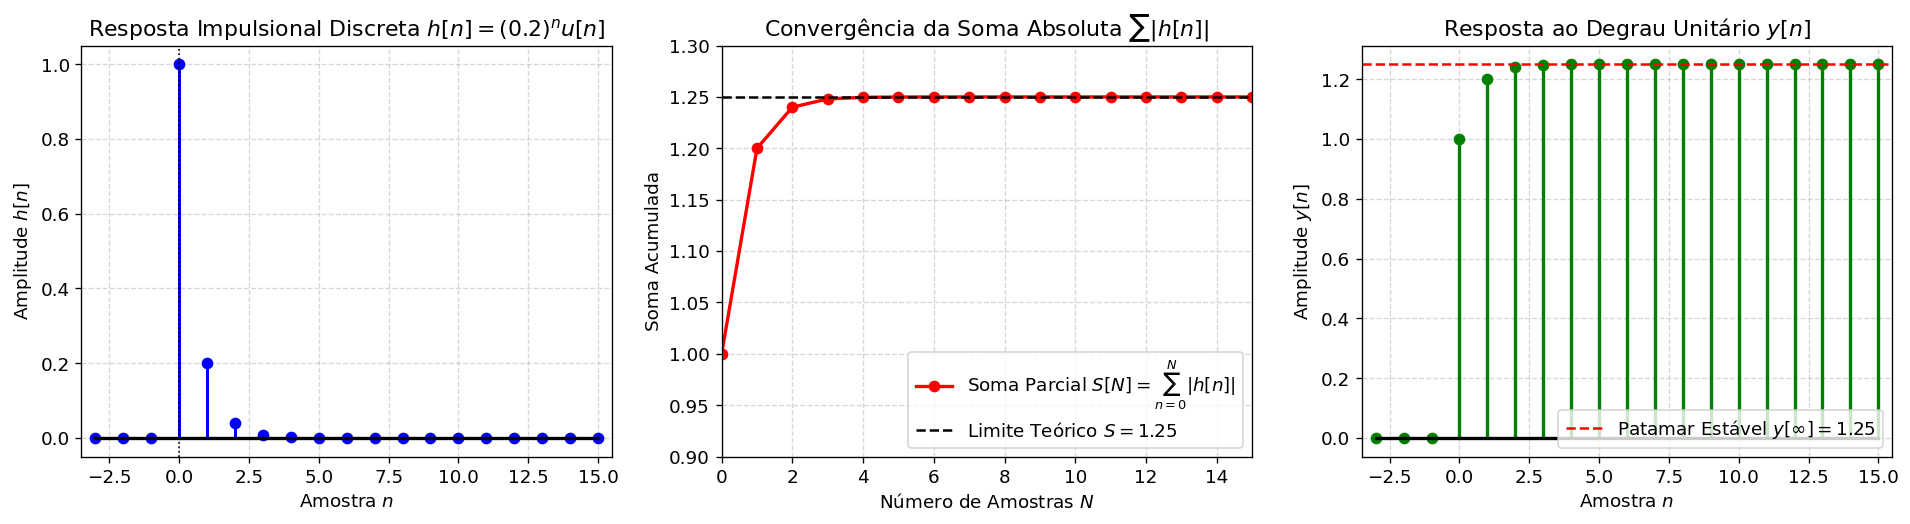

In [5]:
# ====================================================================
# SIMULAÇÃO COMPUTACIONAL — Exercício 2 g): h[n] = (1/5)^n u[n]
# ====================================================================

# 1. Sequência temporal discreta
n_g = np.arange(-3, 16)
h_2g = np.where(n_g >= 0, (0.2)**n_g, 0.0)

# 2. Soma acumulada e valor assintótico teórico
S_teorico = 1.0 / (1.0 - 0.2)  # S = 5/4 = 1.25
n_pos = np.arange(0, 16)
h_pos = (0.2)**n_pos
soma_acumulada = np.cumsum(h_pos)

print(f"--- Exercício 2 g) ---")
print(f"Razão geométrica r = 0.2 (|r| < 1 -> convergente)")
print(f"Soma analítica teórica: S = 1 / (1 - 0.2) = {S_teorico:.4f}")
print(f"Soma acumulada após N = 3 amostras:  {soma_acumulada[3]:.4f}")
print(f"Soma acumulada após N = 10 amostras: {soma_acumulada[10]:.6f}")
print(f"Critério BIBO: S < inf -> SISTEMA ESTÁVEL (BIBO)")

# 3. Resposta ao Degrau Unitário x[n] = u[n] via Convolução Discreta
# y[n] = sum_{k=0}^n (0.2)^k = (1 - 0.2^{n+1}) / (1 - 0.2) = 1.25 * (1 - 0.2^{n+1})
y_degrau_teorico = np.where(n_g >= 0, 1.25 * (1.0 - (0.2)**(n_g + 1)), 0.0)

# Visualização gráfica
fig, axs = plt.subplots(1, 3, figsize=(16, 4.5))

# Subplot 1: Resposta ao Impulso h[n] (stem plot)
markerline, stemlines, baseline = axs[0].stem(n_g, h_2g, linefmt='b-', markerfmt='bo', basefmt='k-')
plt.setp(stemlines, 'linewidth', 1.8)
axs[0].axvline(0, color='black', lw=1.0, linestyle=':')
axs[0].set_title(r'Resposta Impulsional Discreta $h[n] = (0.2)^n u[n]$')
axs[0].set_xlabel(r'Amostra $n$')
axs[0].set_ylabel(r'Amplitude $h[n]$')
axs[0].set_xlim([-3.5, 15.5])

# Subplot 2: Convergência da Série Absoluta
axs[1].plot(n_pos, soma_acumulada, 'ro-', lw=2, label=r'Soma Parcial $S[N] = \sum_{n=0}^N |h[n]|$')
axs[1].axhline(S_teorico, color='black', linestyle='--', lw=1.5,
               label=rf'Limite Teórico $S = {S_teorico:.2f}$')
axs[1].set_title(r'Convergência da Soma Absoluta $\sum |h[n]|$')
axs[1].set_xlabel(r'Número de Amostras $N$')
axs[1].set_ylabel(r'Soma Acumulada')
axs[1].legend(loc='lower right')
axs[1].set_xlim([0, 15])
axs[1].set_ylim([0.9, 1.3])

# Subplot 3: Resposta ao Degrau Discreto y[n] = x[n] * h[n]
axs[2].stem(n_g, y_degrau_teorico, linefmt='g-', markerfmt='go', basefmt='k-')
axs[2].axhline(S_teorico, color='red', linestyle='--', lw=1.5,
               label=rf'Patamar Estável $y[\infty] = {S_teorico:.2f}$')
axs[2].set_title(r'Resposta ao Degrau Unitário $y[n]$')
axs[2].set_xlabel(r'Amostra $n$')
axs[2].set_ylabel(r'Amplitude $y[n]$')
axs[2].legend(loc='lower right')
axs[2].set_xlim([-3.5, 15.5])

plt.tight_layout()
plt.show()


---
## Exercício 2 k)
### Resposta Impulsional: $$h[n] = n \cos\left(\frac{\pi}{4} n\right) \, u[n]$$
*(Oscilador discreto com amplitude modulada por rampa linear $n$)*

---

### Resolução Analítica Passo a Passo

#### 1. Memória (Estático vs. Dinâmico)
* **Condição Teórica**: Um sistema LIT discreto é estático se e só se $h[n] = K \delta[n]$.
* **Análise de $h[n]$**:
  Avaliando algumas amostras de $h[n]$:
  $$h[0] = 0 \cdot \cos(0) = 0$$
  $$h[1] = 1 \cdot \cos\left(\frac{\pi}{4}\right) = \frac{\sqrt{2}}{2} \approx 0.7071 \neq 0$$
  $$h[2] = 2 \cdot \cos\left(\frac{\pi}{2}\right) = 2 \cdot 0 = 0$$
  $$h[3] = 3 \cdot \cos\left(\frac{3\pi}{4}\right) = -3\frac{\sqrt{2}}{2} \approx -2.1213 \neq 0$$
  $$h[4] = 4 \cdot \cos(\pi) = 4 \cdot (-1) = -4 \neq 0$$
  Como $h[n]$ apresenta infinitos valores não nulos para $n > 0$, o sistema depende de entradas passadas.
* **Conclusão**: O sistema **TEM MEMÓRIA (Dinâmico)**.

---

#### 2. Causalidade
* **Condição Teórica**: Um sistema LIT discreto é causal se e só se $h[n] = 0$ para todo $n < 0$.
* **Análise de $h[n]$**:
  Devido à multiplicação explícita pelo degrau unitário $u[n]$:
  $$u[n] = 0, \quad \forall n < 0 \implies h[n] = 0, \quad \forall n < 0$$
* **Conclusão**: O sistema é **CAUSAL**.

---

#### 3. Estabilidade BIBO
* **Condição Teórica**: O sistema é BIBO estável se e só se a resposta ao impulso for absolutamente somável:
  $$S = \sum_{n=-\infty}^{+\infty} |h[n]| < \infty$$
* **Demonstração Analítica da Divergência**:
  $$S = \sum_{n=0}^{+\infty} \left| n \cos\left(\frac{\pi}{4} n\right) \right|$$
  Podemos demonstrar a divergência de forma irrefutável através de dois métodos complementares:

  **Método A (Critério do Termo Geral / Condição Necessária de Convergência)**:
  Uma condição necessária fundamental para que qualquer série numérica $\sum a_n$ convirja é que o seu termo geral convirja para zero no infinito:
  $$\lim_{n \to \infty} |h[n]| = 0$$
  Consideremos a subsequência de índices $n_m = 8m$, onde $m \in \{1, 2, 3, \dots\}$:
  $$\cos\left(\frac{\pi}{4} n_m\right) = \cos\left(\frac{\pi}{4} \cdot 8m\right) = \cos(2\pi m) = 1$$
  Avaliando o termo geral nessa subsequência:
  $$|h[n_m]| = |h[8m]| = 8m \cdot 1 = 8m$$
  Tomando o limite quando $m \to \infty$:
  $$\lim_{m \to \infty} |h[8m]| = \lim_{m \to \infty} 8m = +\infty \neq 0$$
  Como existe uma subsequência cujo termo geral tende para o infinito, o limite $\lim_{n \to \infty} h[n]$ não existe (oscila com amplitude divergente). Logo, a série não pode convergir.

  **Método B (Critério da Minorante)**:
  Como todos os termos da série são não-negativos ($|h[n]| \ge 0$), podemos minorar a soma total pela soma restrita à subsequência dos múltiplos de 8:
  $$S = \sum_{n=0}^{\infty} \left| n \cos\left(\frac{\pi}{4} n\right) \right| \ge \sum_{m=1}^{\infty} |h[8m]| = \sum_{m=1}^{\infty} 8m = 8 \sum_{m=1}^{\infty} m$$
  A série $\sum_{m=1}^{\infty} m = 1 + 2 + 3 + \dots = +\infty$ é a série dos números naturais, que diverge manifestamente para $+\infty$.
  Pelo critério da comparação de séries com termos positivos, $S = +\infty$.

* **Conclusão**: A soma diverge ($S = \infty$). O sistema é **INSTÁVEL (BIBO)**.
  *(Em Engenharia, excitar este sistema com um sinal perfeitamente limitado como o degrau unitário $x[n] = u[n]$ provoca uma resposta oscilatória com amplitude crescente sem limite, levando à instabilidade e saturação dos circuitos).*


--- Exercício 2 k) ---
Amostra h[0]: 0.00
Amostra h[1]: 0.7071 (aprox sqrt(2)/2)
Amostra h[4]: -4.00
Amostra h[8]: 8.00 (8 * cos(2*pi) = 8)
Amostra h[16]: 16.00 (16 * cos(4*pi) = 16)
Amostra h[24]: 24.00 (24 * cos(6*pi) = 24)
Soma acumulada após N = 10: 29.68
Soma acumulada após N = 20: 130.71
Soma acumulada após N = 32: 325.02
Conclusão: Série diverge quadraticamente -> SISTEMA INSTÁVEL (BIBO)


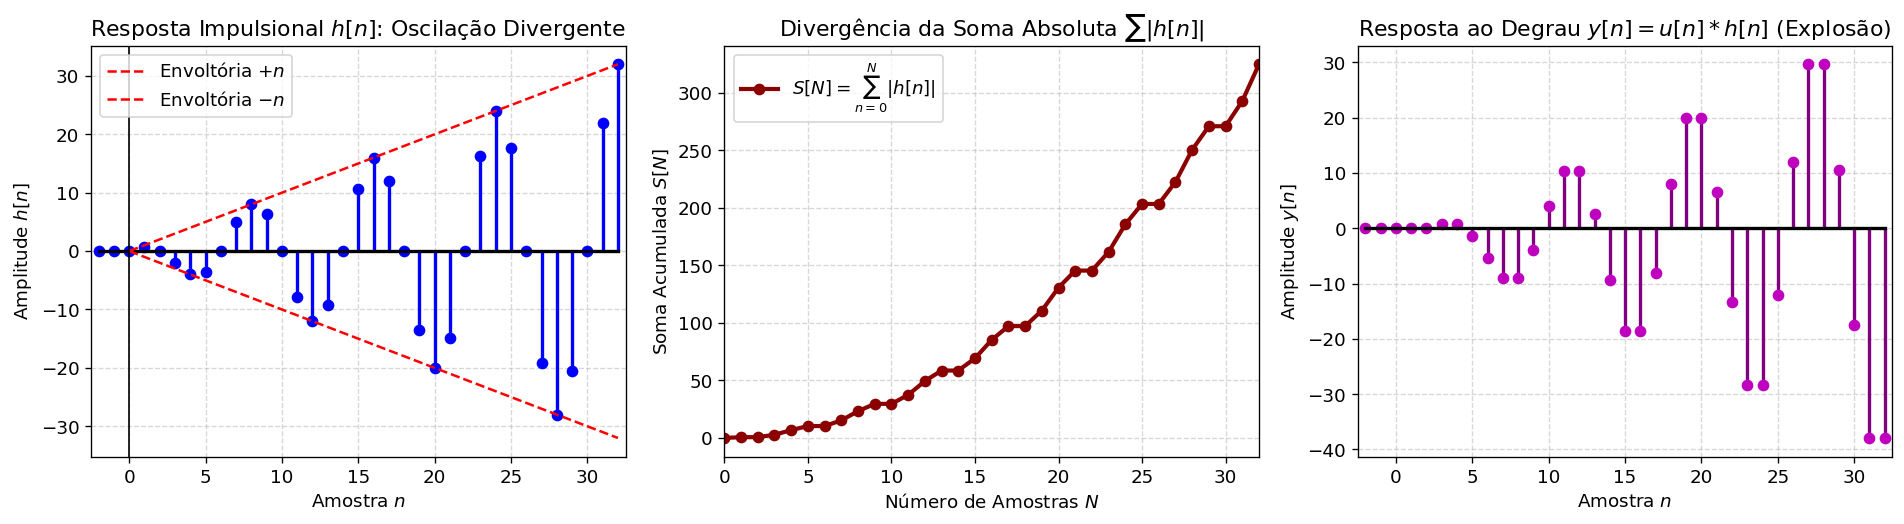

In [6]:
# ====================================================================
# SIMULAÇÃO COMPUTACIONAL — Exercício 2 k): h[n] = n cos(pi/4 n) u[n]
# ====================================================================

# 1. Vetor temporal discreto e cálculo de h[n]
n_k = np.arange(-2, 33)
h_2k = np.where(n_k >= 0, n_k * np.cos(np.pi / 4.0 * n_k), 0.0)

# 2. Soma acumulada dos módulos para evidenciar a divergência quadrática
n_pos_k = np.arange(0, 33)
h_pos_k = np.abs(n_pos_k * np.cos(np.pi / 4.0 * n_pos_k))
soma_acumulada_k = np.cumsum(h_pos_k)

print(f"--- Exercício 2 k) ---")
print(f"Amostra h[0]: {h_2k[2]:.2f}")
print(f"Amostra h[1]: {h_2k[3]:.4f} (aprox sqrt(2)/2)")
print(f"Amostra h[4]: {h_2k[6]:.2f}")
print(f"Amostra h[8]: {h_2k[10]:.2f} (8 * cos(2*pi) = 8)")
print(f"Amostra h[16]: {h_2k[18]:.2f} (16 * cos(4*pi) = 16)")
print(f"Amostra h[24]: {h_2k[26]:.2f} (24 * cos(6*pi) = 24)")
print(f"Soma acumulada após N = 10: {soma_acumulada_k[10]:.2f}")
print(f"Soma acumulada após N = 20: {soma_acumulada_k[20]:.2f}")
print(f"Soma acumulada após N = 32: {soma_acumulada_k[32]:.2f}")
print("Conclusão: Série diverge quadraticamente -> SISTEMA INSTÁVEL (BIBO)")

# 3. Resposta a uma Entrada Limitada Constante x[n] = u[n] (Convolução Discreta)
# y[n] = sum_{k=0}^n h[k]
y_degrau_k = np.convolve(np.where(n_k >= 0, 1.0, 0.0), h_2k, mode='full')[:len(n_k)]

# Visualização gráfica
fig, axs = plt.subplots(1, 3, figsize=(16, 4.5))

# Subplot 1: Resposta ao Impulso com envoltórias lineares divergentes +- n
axs[0].stem(n_k, h_2k, linefmt='b-', markerfmt='bo', basefmt='k-')
axs[0].plot(n_pos_k, n_pos_k, 'r--', lw=1.5, label=r'Envoltória $+n$')
axs[0].plot(n_pos_k, -n_pos_k, 'r--', lw=1.5, label=r'Envoltória $-n$')
axs[0].axvline(0, color='black', lw=1.0)
axs[0].set_title(r'Resposta Impulsional $h[n]$: Oscilação Divergente')
axs[0].set_xlabel(r'Amostra $n$')
axs[0].set_ylabel(r'Amplitude $h[n]$')
axs[0].legend(loc='upper left')
axs[0].set_xlim([-2.5, 32.5])

# Subplot 2: Divergência da Soma Acumulada
axs[1].plot(n_pos_k, soma_acumulada_k, 'darkred', lw=2.5, marker='o',
            label=r'$S[N] = \sum_{n=0}^N |h[n]|$')
axs[1].set_title(r'Divergência da Soma Absoluta $\sum |h[n]|$')
axs[1].set_xlabel(r'Número de Amostras $N$')
axs[1].set_ylabel(r'Soma Acumulada $S[N]$')
axs[1].legend(loc='upper left')
axs[1].set_xlim([0, 32])

# Subplot 3: Saída y[n] ao Degrau u[n] evidenciando instabilidade física
axs[2].stem(n_k, y_degrau_k, linefmt='purple', markerfmt='mo', basefmt='k-')
axs[2].set_title(r'Resposta ao Degrau $y[n] = u[n] * h[n]$ (Explosão)')
axs[2].set_xlabel(r'Amostra $n$')
axs[2].set_ylabel(r'Amplitude $y[n]$')
axs[2].set_xlim([-2.5, 32.5])

plt.tight_layout()
plt.show()


---
## 3. Quadro Síntese de Classificação dos Sistemas

A tabela abaixo consolida de forma rigorosa as propriedades de cada um dos cinco sistemas LIT analisados na Folha Prática TP04c:

| Alínea | Expressão de $h(t)$ / $h[n]$ | Domínio | Memória | Causalidade | Estabilidade (BIBO) | Justificação Sintética |
| :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| **2 a)** | $e^{-2t} u(t - 2)$ | TC | **Com Memória** | **Causal** | **Estável** | $h(t) \neq K\delta(t)$; $h(t)=0, \forall t<0$; $I = \frac{e^{-4}}{2} < \infty$ |
| **2 b)** | $e^{-4t} u(3 - t)$ | TC | **Com Memória** | **Não Causal** | **Instável** | Suporte $t \le 3$; $h(-1)=e^4 \neq 0$; $I = \int_{-\infty}^3 e^{-4t}dt = \infty$ |
| **2 f)** | $6e^{-t}\cos(2t)\delta(t)$ | TC | **Sem Memória** | **Causal** | **Estável** | $g(0)\delta(t) = 6\delta(t)$; sem dispersão temporal; $I = 6 < \infty$ |
| **2 g)** | $(1/5)^n u[n]$ | TD | **Com Memória** | **Causal** | **Estável** | $h[n] \neq K\delta[n]$; $h[n]=0, \forall n<0$; série geométrica $S = 1.25 < \infty$ |
| **2 k)** | $n\cos(\frac{\pi}{4}n) u[n]$ | TD | **Com Memória** | **Causal** | **Instável** | $h[n] \neq K\delta[n]$; $h[n]=0, \forall n<0$; termo geral $h[8m]=8m \to \infty \implies S=\infty$ |

---

## 4. Recomendações Pedagógicas & Regras de Ouro para Engenharia

Como futuro Engenheiro Electrotécnico, memorize estas diretrizes fundamentais para análise rápida e sem erros em problemas práticos, frequências e exames:

1. **Memória em Sistemas LIT**:
   - Um sistema LIT é **Sem Memória (Estático)** **SE E SÓ SE** a sua resposta impulsional for um impulso puro centrado na origem: $h(t) = K\delta(t)$ ou $h[n] = K\delta[n]$.
   - Se $h(t)$ ou $h[n]$ tiver qualquer valor não nulo fora da origem ($t \neq 0$ ou $n \neq 0$), o sistema é obrigatoriamente **Com Memória (Dinâmico)**.
   - Todo o sistema sem memória é **intrinsecamente causal** (pois não depende de instantes futuros).

2. **Causalidade e Implementação Física**:
   - Olhe imediatamente para o suporte temporal de $h(t)$ ou $h[n]$. Se existir **qualquer instante $t < 0$** (ou $n < 0$) onde $h \neq 0$, o sistema é **Não Causal**.
   - Cuidado com degraus invertidos como $u(t_0 - t)$: eles ativam a função para $t \le t_0$, o que abrange todo o infinito negativo ($t \to -\infty$), gerando quase sempre não causalidade!

3. **Estabilidade BIBO e o Critério de Convergência**:
   - **Tempo Contínuo**: A integral $\int_{-\infty}^{+\infty} |h(t)| dt$ tem de convergir. Exponenciais $e^{at} u(t)$ com $a < 0$ convergem para $t \to +\infty$; mas se o sinal existir para $t \to -\infty$, exponenciais com expoente negativo explodem (como sucedeu na alínea *2b*).
   - **Tempo Discreto**: A soma $\sum_{n=-\infty}^{+\infty} |h[n]|$ tem de convergir. Para sequências geométricas $a^n u[n]$, a estabilidade exige estritamente $|a| < 1$.
   - **Teste Rápido de Divergência**: Se o termo geral $h[n]$ ou $h(t)$ não tender para zero quando o tempo tende para o infinito (ou tiver termos que crescem como polinómios $n$ ou $t$), o sistema é **garantidamente INSTÁVEL** (como na alínea *2k*).


In [7]:
# ====================================================================
# TABELA SÍNTESE COMPUTACIONAL DOS RESULTADOS (PANDAS)
# ====================================================================
dados_resumo = {
    "Exercício": ["2 a)", "2 b)", "2 f)", "2 g)", "2 k)"],
    "Expressão h": [
        "exp(-2t) u(t-2)",
        "exp(-4t) u(3-t)",
        "6 exp(-t) cos(2t) delta(t) = 6 delta(t)",
        "(1/5)^n u[n]",
        "n cos(pi/4 n) u[n]"
    ],
    "Domínio": ["TC", "TC", "TC", "TD", "TD"],
    "Memória": ["Com Memória", "Com Memória", "Sem Memória (Estático)", "Com Memória", "Com Memória"],
    "Causalidade": ["Causal", "Não Causal", "Causal", "Causal", "Causal"],
    "Estabilidade (BIBO)": ["Estável", "Instável", "Estável", "Estável", "Instável"],
    "Integral / Soma": ["I = exp(-4)/2 ≈ 0.0092", "I = +inf", "I = 6.0", "S = 5/4 = 1.25", "S = +inf"]
}

df_resumo = pd.DataFrame(dados_resumo)
print("=== QUADRO SÍNTESE DE CLASSIFICAÇÃO DOS SISTEMAS LIT ===")
display_str = df_resumo.to_string(index=False)
print(display_str)


=== QUADRO SÍNTESE DE CLASSIFICAÇÃO DOS SISTEMAS LIT ===
Exercício                             Expressão h Domínio                Memória Causalidade Estabilidade (BIBO)        Integral / Soma
     2 a)                         exp(-2t) u(t-2)      TC            Com Memória      Causal             Estável I = exp(-4)/2 ≈ 0.0092
     2 b)                         exp(-4t) u(3-t)      TC            Com Memória  Não Causal            Instável               I = +inf
     2 f) 6 exp(-t) cos(2t) delta(t) = 6 delta(t)      TC Sem Memória (Estático)      Causal             Estável                I = 6.0
     2 g)                            (1/5)^n u[n]      TD            Com Memória      Causal             Estável         S = 5/4 = 1.25
     2 k)                      n cos(pi/4 n) u[n]      TD            Com Memória      Causal            Instável               S = +inf
